# US Diabetes Dataset — EDA, Visualization and Preprocessing

This notebook follows a simple, step-by-step Pandas style.

**Dataset note:** `diabetic_data.csv` is a hospital encounter dataset for patients with diabetes. Its `readmitted` column describes hospital readmission (`NO`, `>30`, `<30`); it does not directly diagnose diabetes.

**Before running:** Put `diabetic_data.csv` (or `diabetic_data_preprocessed_stage1.csv`) in the same folder as this notebook, then use **Kernel → Restart & Run All**. The cells are meant to be run top to bottom.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the dataset

In [2]:
from pathlib import Path

# Look for the data next to the notebook (no hard-coded C:\\ path).
# "?" is the dataset's missing-value marker, so read it as NaN straight away.
candidates = ["diabetic_data.csv", "diabetic_data_preprocessed_stage1.csv"]
data_path = next((Path(p) for p in candidates if Path(p).exists()), None)
if data_path is None:
    raise FileNotFoundError(f"Put one of {candidates} in {Path.cwd()}")

df = pd.read_csv(data_path, na_values=["?"], low_memory=False)
print("Loaded:", data_path)
df.head()

Loaded: diabetic_data_preprocessed_stage1.csv


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 3. Understand the data

In [3]:
print("Rows and columns:", df.shape)


Rows and columns: (101766, 50)


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [5]:

df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,NaN,NaN,NaN,165201645.622978,102640295.983457,12522.0,84961194.0,152388987.0,230270887.5,443867222.0
patient_nbr,101766.0,NaN,NaN,NaN,54330400.694947,38696359.346534,135.0,23413221.0,45505143.0,87545949.75,189502619.0
race,99493,5,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,3197,9,[75-100),1336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766.0,NaN,NaN,NaN,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,NaN,NaN,NaN,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,NaN,NaN,NaN,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0


## 4. Check duplicate rows

In [6]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


## 5. Convert '?' to missing values

In [7]:
# `df` stays as the untouched original; `data` is the working copy used for EDA.
data = df.copy()
data = data.replace("?", np.nan)   # safety net in case "?" slipped through

data.isnull().sum().sort_values(ascending=False).head(20)

weight                      98569
max_glu_serum               96420
A1Cresult                   84748
medical_specialty           49949
payer_code                  40256
race                         2273
diag_3                       1423
diag_2                        358
diag_1                         21
patient_nbr                     0
time_in_hospital                0
admission_source_id             0
num_lab_procedures              0
encounter_id                    0
admission_type_id               0
discharge_disposition_id        0
gender                          0
age                             0
number_inpatient                0
number_emergency                0
dtype: int64

## 6. Missing-value summary

In [8]:
missing_count = data.isnull().sum()
missing_percent = (missing_count / len(data)) * 100

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
})

missing_summary = missing_summary.sort_values("missing_percent", ascending=False)
missing_summary.head(20)


,missing_count,missing_percent
weight,98569,96.858479
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636
patient_nbr,0,0.000000


## 7. Visualization: missing values

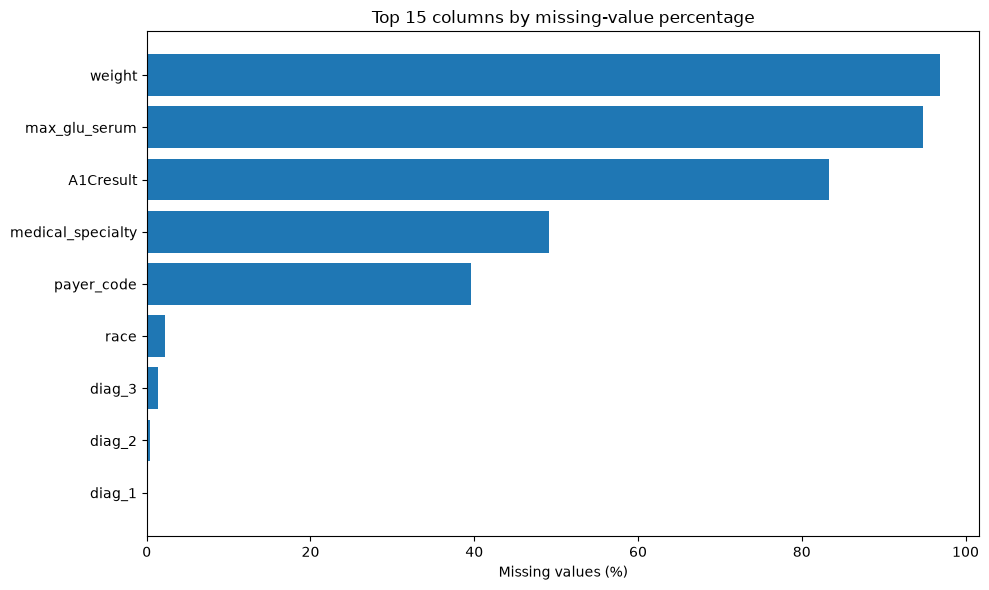

In [9]:
missing_plot = missing_summary[missing_summary["missing_count"] > 0].head(15)

plt.figure(figsize=(10, 6))
plt.barh(missing_plot.index[::-1], missing_plot["missing_percent"].iloc[::-1])
plt.xlabel("Missing values (%)")
plt.title("Top 15 columns by missing-value percentage")
plt.tight_layout()
plt.show()


## 8. Explore the target: readmission

In [10]:
data["readmitted"].value_counts(dropna=False)


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

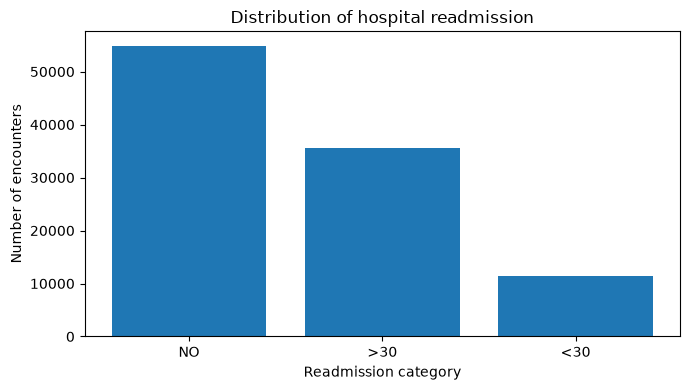

In [11]:
readmission_counts = data["readmitted"].value_counts()

plt.figure(figsize=(7, 4))
plt.bar(readmission_counts.index.astype(str), readmission_counts.values)
plt.xlabel("Readmission category")
plt.ylabel("Number of encounters")
plt.title("Distribution of hospital readmission")
plt.tight_layout()
plt.show()


In [12]:
readmission_percent = data["readmitted"].value_counts(normalize=True) * 100
readmission_percent


readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64

## 9. Explore age

In [13]:
data["age"].value_counts().sort_index()


age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

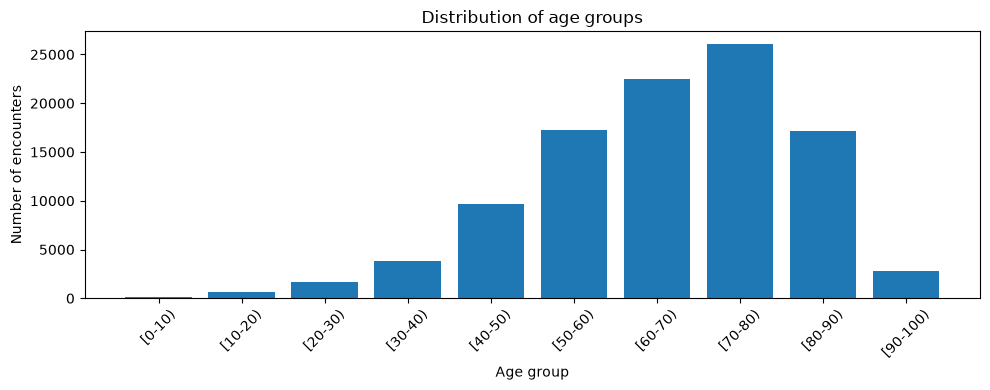

In [14]:
age_counts = data["age"].value_counts().sort_index()

plt.figure(figsize=(10, 4))
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xlabel("Age group")
plt.ylabel("Number of encounters")
plt.title("Distribution of age groups")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 10. Explore gender

In [15]:
data["gender"].value_counts(dropna=False)


gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

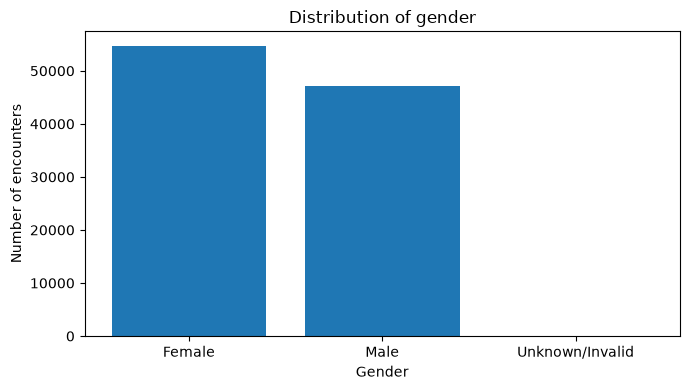

In [16]:
gender_counts = data["gender"].value_counts(dropna=False)

plt.figure(figsize=(7, 4))
plt.bar(gender_counts.index.astype(str), gender_counts.values)
plt.xlabel("Gender")
plt.ylabel("Number of encounters")
plt.title("Distribution of gender")
plt.tight_layout()
plt.show()


## 11. Readmission by age group

In [17]:
readmission_by_age = pd.crosstab(data["age"], data["readmitted"], normalize="index") * 100
readmission_by_age


readmitted,<30,>30,NO
age,,,
[0-10),1.863354,16.149068,81.987578
[10-20),5.788712,32.416787,61.794501
[20-30),14.242607,30.778515,54.978877
[30-40),11.231788,31.443709,57.324503
[40-50),10.604027,33.846154,55.549819
[50-60),9.666203,34.289522,56.044274
[60-70),11.128408,35.124316,53.747276
[70-80),11.773055,36.347246,51.879699
[80-90),12.083503,36.186544,51.729953


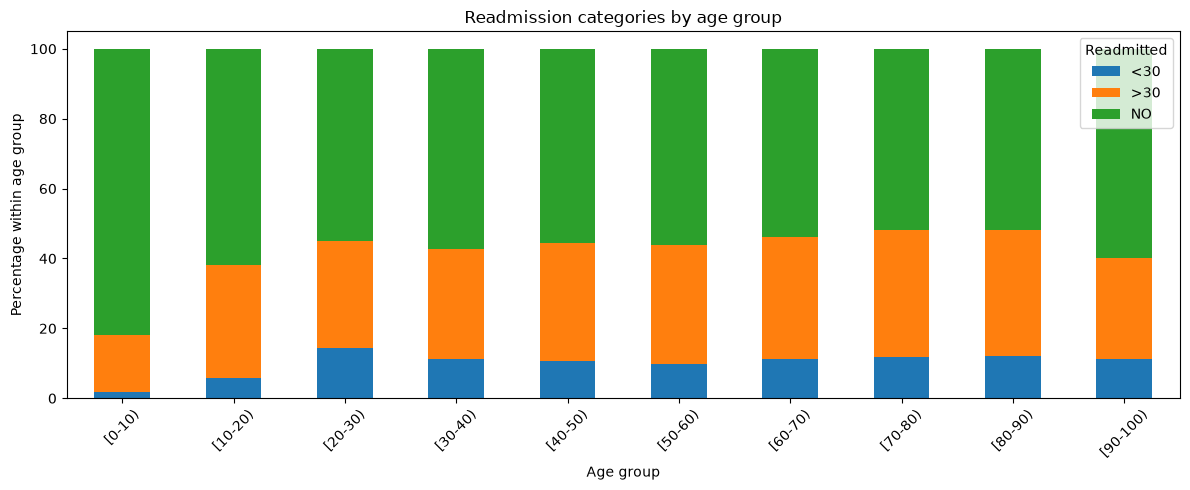

In [18]:
readmission_by_age.plot(kind="bar", stacked=True, figsize=(12, 5))
plt.xlabel("Age group")
plt.ylabel("Percentage within age group")
plt.title("Readmission categories by age group")
plt.legend(title="Readmitted")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 12. Explore admission type

In [19]:
data["admission_type_id"].value_counts(dropna=False).sort_index()

admission_type_id
1    53990
2    18480
3    18869
4       10
5     4785
6     5291
7       21
8      320
Name: count, dtype: int64

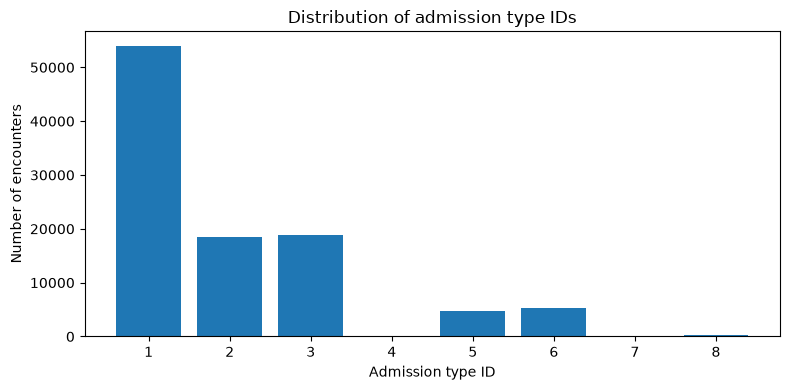

In [20]:
admission_counts = data["admission_type_id"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(admission_counts.index.astype(str), admission_counts.values)
plt.xlabel("Admission type ID")
plt.ylabel("Number of encounters")
plt.title("Distribution of admission type IDs")
plt.tight_layout()
plt.show()

## 13. Explore glucose and A1C result categories

In [21]:
print("Max glucose serum results:")
print(data["max_glu_serum"].value_counts(dropna=False))

print("\nA1C results:")
print(data["A1Cresult"].value_counts(dropna=False))

Max glucose serum results:
max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64

A1C results:
A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64


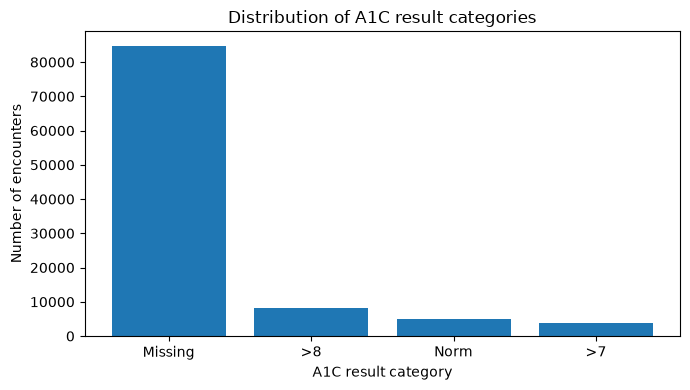

In [22]:
a1c_counts = data["A1Cresult"].fillna("Missing").value_counts()

plt.figure(figsize=(7, 4))
plt.bar(a1c_counts.index.astype(str), a1c_counts.values)
plt.xlabel("A1C result category")
plt.ylabel("Number of encounters")
plt.title("Distribution of A1C result categories")
plt.tight_layout()
plt.show()


## 14. Number of medications

In [23]:
data["num_medications"].describe()

count    101766.000000
mean         16.021844
std           8.127566
min           1.000000
25%          10.000000
50%          15.000000
75%          20.000000
max          81.000000
Name: num_medications, dtype: float64

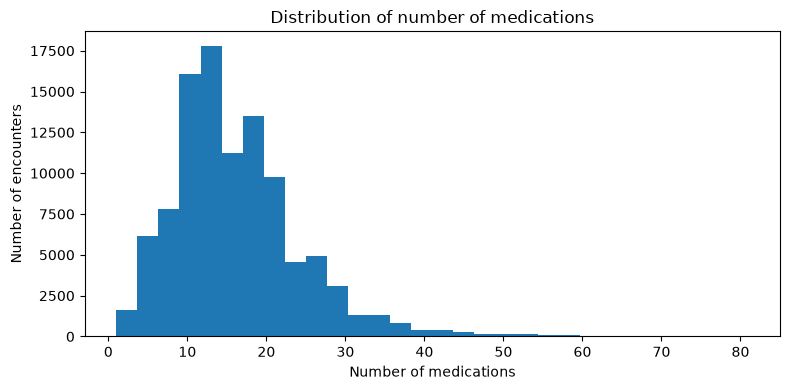

In [24]:
plt.figure(figsize=(8, 4))
plt.hist(data["num_medications"].dropna(), bins=30)
plt.xlabel("Number of medications")
plt.ylabel("Number of encounters")
plt.title("Distribution of number of medications")
plt.tight_layout()
plt.show()


## 15. Readmission by A1C result

In [25]:
readmission_by_a1c = pd.crosstab(
    data["A1Cresult"].fillna("Missing"),
    data["readmitted"],
    normalize="index"
) * 100

readmission_by_a1c

readmitted,<30,>30,NO
A1Cresult,,,
>7,10.047219,34.102833,55.849948
>8,9.870983,35.309153,54.819864
Missing,11.423278,35.098173,53.478548
Norm,9.659319,32.044088,58.296593


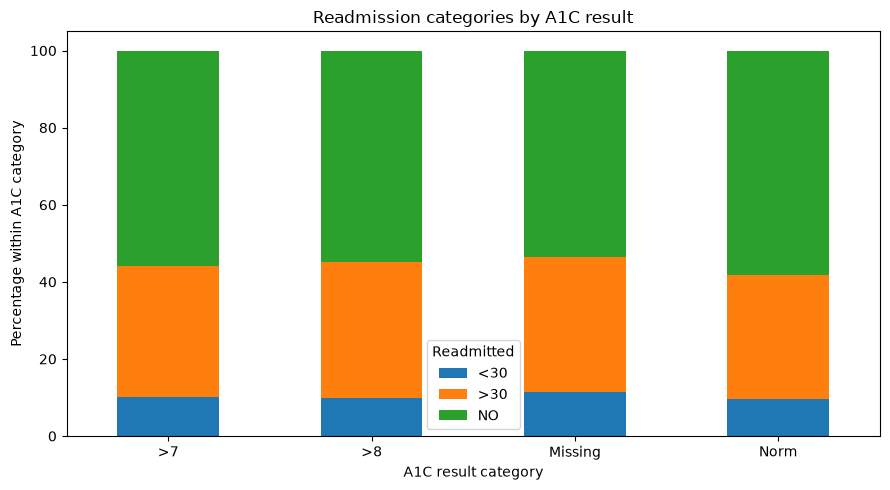

In [26]:
readmission_by_a1c.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.xlabel("A1C result category")
plt.ylabel("Percentage within A1C category")
plt.title("Readmission categories by A1C result")
plt.legend(title="Readmitted")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 16. Preprocessing notes

### What we have done
- Loaded and inspected the dataset.
- Checked duplicates.
- Replaced the `?` markers with missing values in `data`.
- Summarized missing values.
- Explored readmission, age, gender, admission type, A1C results and medication counts with charts.

### Important decisions still needed
- Do not automatically delete every row with a missing value; some columns have a large amount of missing data.
- Decide which columns to retain based on the prediction goal.
- Check identifiers such as `encounter_id` and `patient_nbr` before modeling.
- Encode categorical columns only after deciding the model and features.
- Split into training and test sets before fitting imputers, scalers or encoders to avoid data leakage.
- This dataset supports a hospital-readmission analysis, not a direct diabetes diagnosis.


## 17. Save the stage-one cleaned dataset
This is the cleaned data **before** encoding, so the plots and later steps can still use the original columns.

In [27]:
data.to_csv("diabetic_data_preprocessed_stage1.csv", index=False)
print("Saved: diabetic_data_preprocessed_stage1.csv", data.shape)

Saved: diabetic_data_preprocessed_stage1.csv (101766, 50)


## 18. Checking for outliers

Numeric columns checked: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


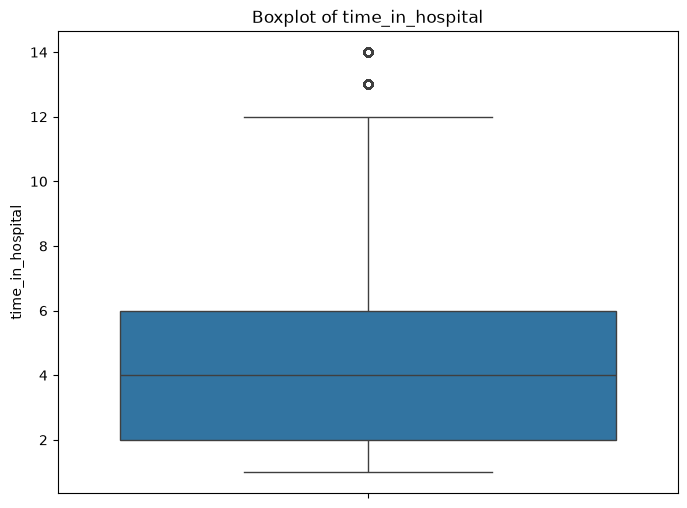

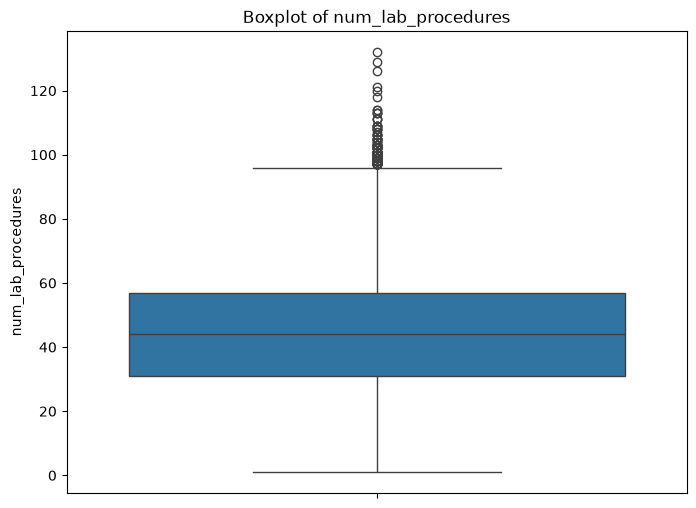

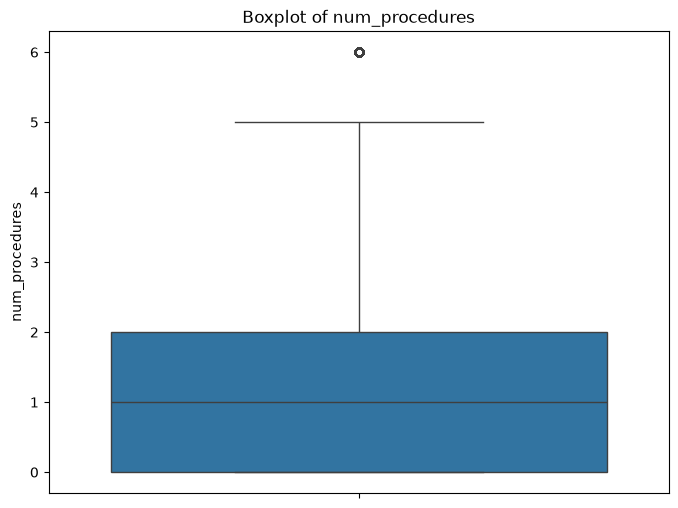

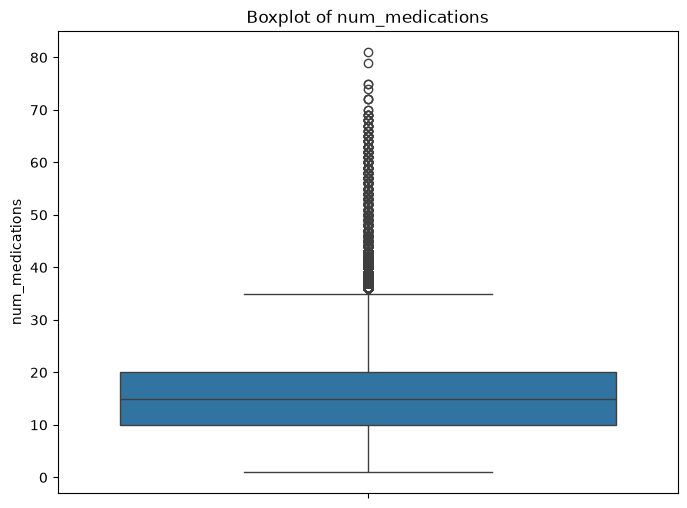

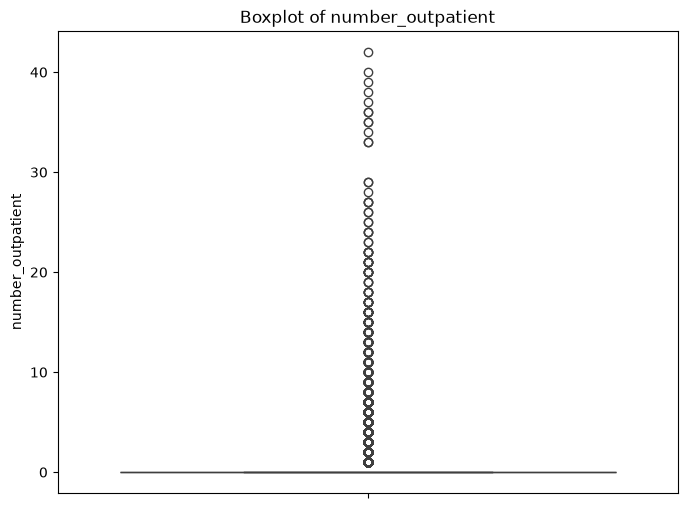

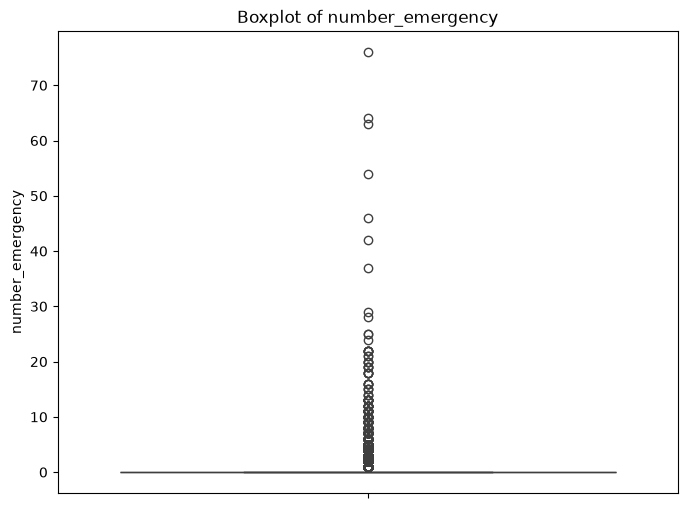

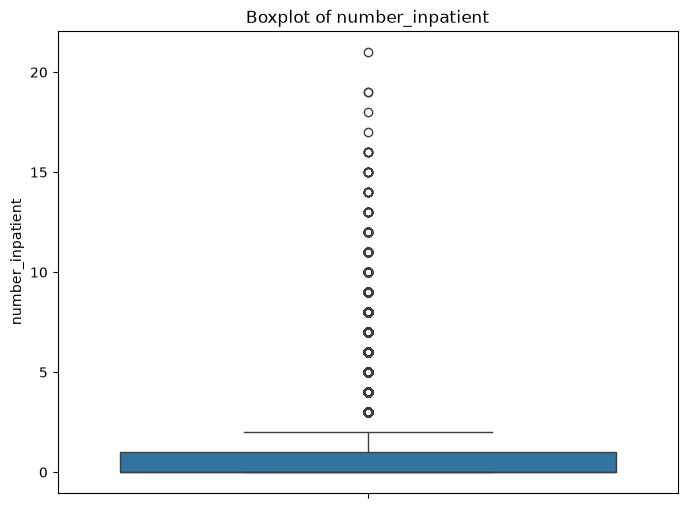

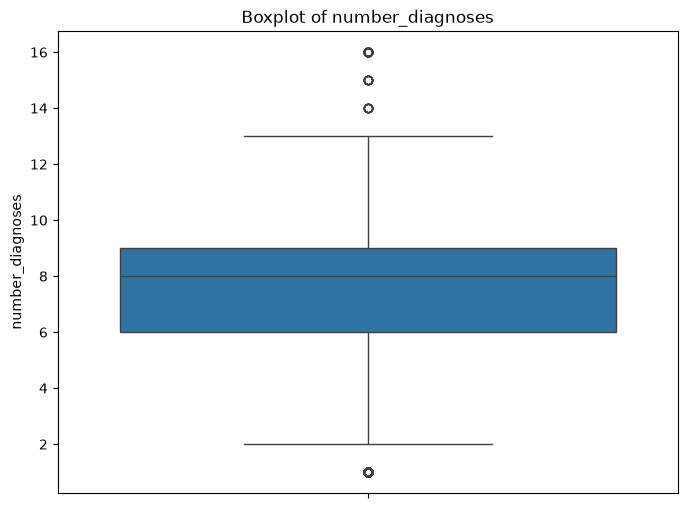

In [28]:
# Boxplots show outliers as points beyond the whiskers.
skip = ["encounter_id", "patient_nbr", "discharge_disposition_id",
        "admission_source_id", "admission_type_id"]
outlier_analysis = [
    col for col in data.columns
    if pd.api.types.is_numeric_dtype(data[col]) and col not in skip
]
print("Numeric columns checked:", outlier_analysis)

for col in outlier_analysis:
    plt.figure(figsize=(8, 6))
    sns.boxplot(data=data, y=col)
    plt.title(f"Boxplot of {col}")
    plt.show()

## 19. Removal of outliers (IQR rule)

Rows: 101766 -> 93078 (8688 removed)


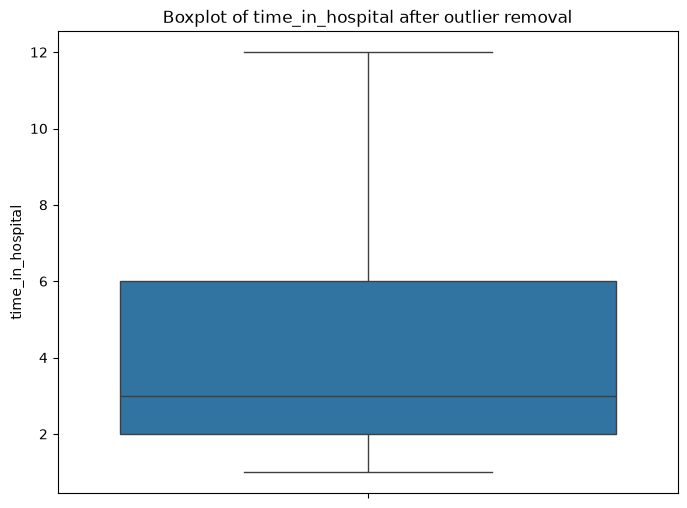

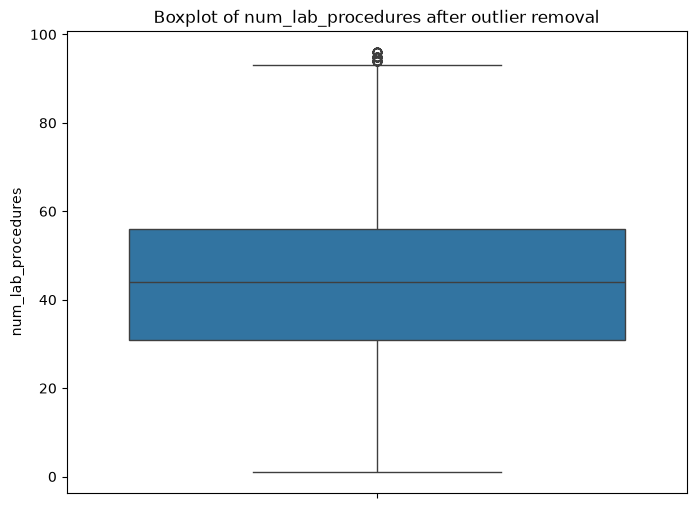

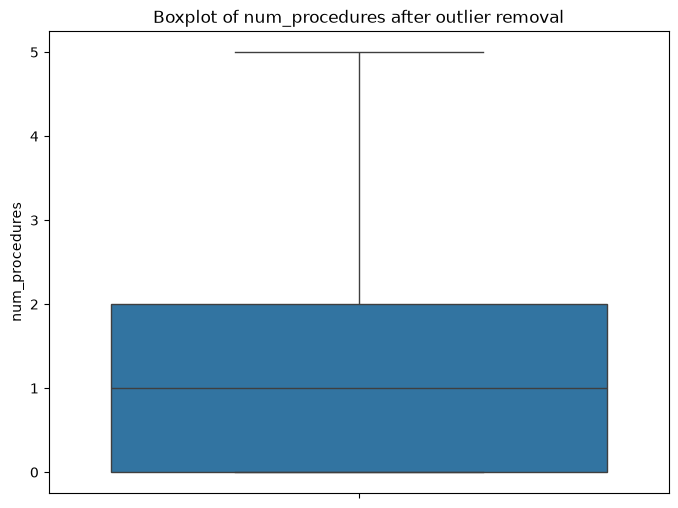

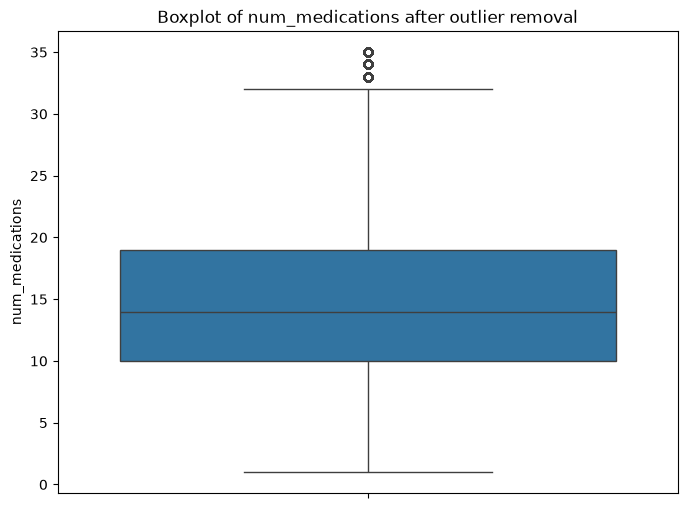

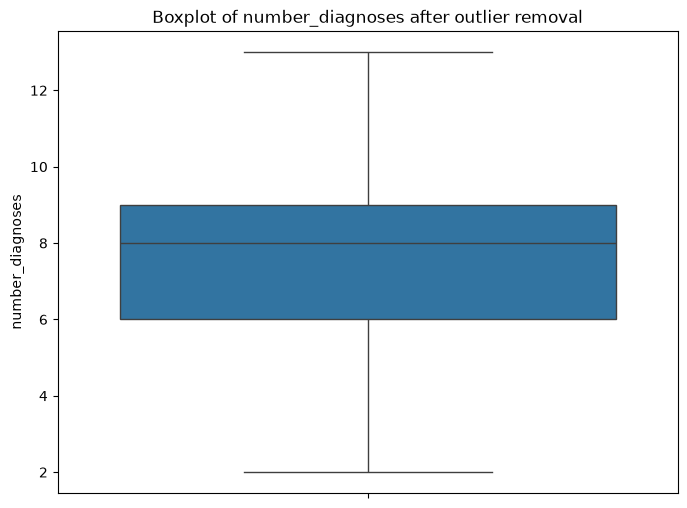

In [29]:
outlier_columns = ["time_in_hospital", "num_lab_procedures", "num_procedures",
                   "num_medications", "number_diagnoses"]

rows_before = len(data)
mask = pd.Series(True, index=data.index)

for col in outlier_columns:
    values = pd.to_numeric(data[col], errors="coerce")
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask &= values.between(lower, upper) | values.isna()

data_no_outliers = data.loc[mask].copy()
print(f"Rows: {rows_before} -> {len(data_no_outliers)} "
      f"({rows_before - len(data_no_outliers)} removed)")

for col in outlier_columns:
    plt.figure(figsize=(8, 6))
    sns.boxplot(data=data_no_outliers, y=col)
    plt.title(f"Boxplot of {col} after outlier removal")
    plt.show()

## 20. Machine learning preparation

All encoding happens **here**, on a new DataFrame (`ml`), so the EDA DataFrames above are never overwritten.

In [30]:
ml = data_no_outliers.copy()

# 1) Drop the 3 rows with unknown gender, then encode gender
ml = ml[ml["gender"].isin(["Female", "Male"])].copy()
ml["gender"] = ml["gender"].map({"Female": 0, "Male": 1})

# 2) Age interval -> midpoint
age_map = {
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
    "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
    "[80-90)": 85, "[90-100)": 95
}
ml["age"] = ml["age"].map(age_map)

# 3) weight is ~97% missing, so it is dropped rather than encoded
print(f"weight missing: {ml['weight'].isna().mean():.1%} -> dropping column")
ml = ml.drop(columns=["weight"])

# 4) Medication status -> numeric codes
drug_cols = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide",
    "glimepiride", "acetohexamide", "glipizide", "glyburide",
    "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide", "examide",
    "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone"
]
drug_map = {"No": 0, "Steady": 1, "Up": 2, "Down": 3}
for col in drug_cols:
    ml[col] = ml[col].map(drug_map)

# 5) Binary columns and the target
ml["change"] = ml["change"].map({"No": 0, "Ch": 1})
ml["diabetesMed"] = ml["diabetesMed"].map({"No": 0, "Yes": 1})
ml["readmitted"] = ml["readmitted"].map({"NO": 0, ">30": 1, "<30": 2})

# 6) Diagnosis codes: ~800 distinct ICD-9 codes would create ~2,400 dummy
#    columns, so group them into broad disease categories first.
def icd9_group(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith(("V", "E")):
        return "Other"
    n = float(code)
    if 250 <= n < 251:                      return "Diabetes"
    if 390 <= n <= 459 or n == 785:         return "Circulatory"
    if 460 <= n <= 519 or n == 786:         return "Respiratory"
    if 520 <= n <= 579 or n == 787:         return "Digestive"
    if 800 <= n <= 999:                     return "Injury"
    if 710 <= n <= 739:                     return "Musculoskeletal"
    if 580 <= n <= 629 or n == 788:         return "Genitourinary"
    if 140 <= n <= 239:                     return "Neoplasms"
    return "Other"

for col in ["diag_1", "diag_2", "diag_3"]:
    ml[col] = ml[col].map(icd9_group)

# 7) Remaining text columns: NaN means "not recorded" -> its own category
for col in ["max_glu_serum", "A1Cresult"]:
    ml[col] = ml[col].fillna("Not tested")
for col in ["payer_code", "medical_specialty", "race"]:
    ml[col] = ml[col].fillna("Missing")

print(ml[["age", "gender", "change", "readmitted"]].isna().sum())

weight missing: 96.9% -> dropping column
age           0
gender        0
change        0
readmitted    0
dtype: int64


## 21. Train/test split and standardization and ML STUFFS USING READMITTED AS TARGET COLUMN

In [31]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

TARGET = "readmitted"          # change to "change" if that was your intended target

# Columns that must not be used as features (identifiers, sensitive attributes, target)
drop_cols = ["encounter_id", "patient_nbr", "admission_type_id",
             "discharge_disposition_id", "admission_source_id",
             "race", "gender", TARGET]

# Keep patient_nbr to split by patient (one patient has many encounters)
groups = ml["patient_nbr"]
y = ml[TARGET]
X = ml.drop(columns=drop_cols)

# One-hot encode the remaining text columns
X = pd.get_dummies(X, columns=X.select_dtypes(include=["object", "string"]).columns,
                   dtype="int64")
print("Feature matrix:", X.shape, "| non-numeric columns:",
      X.select_dtypes(exclude="number").shape[1])
print("Missing values:", X.isna().sum().sum())

# Split so the same patient never appears in both train and test (prevents leakage)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
x_train, x_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train:", x_train.shape, "Test:", x_test.shape)
print("Patients in both sets:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Feature matrix: (93075, 162) | non-numeric columns: 0
Missing values: 0
Train: (74426, 162) Test: (18649, 162)
Patients in both sets: 0


In [32]:
# Fit the scaler on the training data only, then apply it to both sets
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print(x_train_scaled.shape, x_test_scaled.shape)
print(y_train.value_counts(normalize=True).round(3).to_dict())

(74426, 162) (18649, 162)
{0: 0.536, 1: 0.351, 2: 0.113}


Logistic Regression

In [33]:
from sklearn.linear_model import LogisticRegression
from warnings import filterwarnings
filterwarnings('ignore')
model=LogisticRegression()
model.fit(x_train_scaled,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

Logistic Regression Model Evaluation:
Accuracy score: 0.5680733551396858
Classification report
              precision    recall  f1-score   support

           0       0.58      0.89      0.71      9946
           1       0.50      0.26      0.34      6658
           2       0.36      0.01      0.02      2045

    accuracy                           0.57     18649
   macro avg       0.48      0.39      0.36     18649
weighted avg       0.53      0.57      0.50     18649

Confusion Matrix:
[[8841 1091   14]
 [4899 1727   32]
 [1382  637   26]]


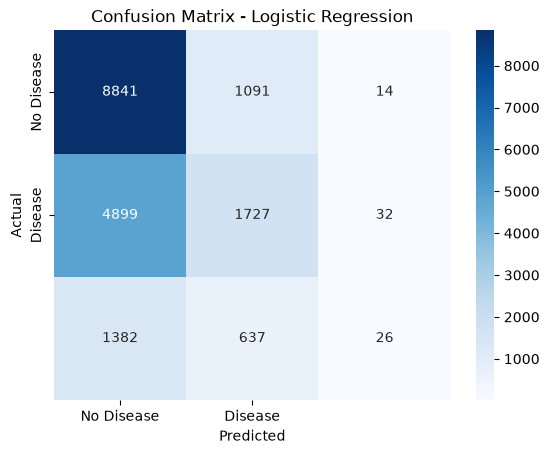

In [ ]:
y_pred= model.predict(x_test_scaled)

print("Logistic Regression Model Evaluation:")
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
accuracy=accuracy_score(y_test,y_pred)
print(f"Accuracy score: {accuracy}")
classification=classification_report(y_test,y_pred)
print("Classification report")
print(classification)
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Readmission', 'Readmitted >30 days', 'Readmitted <30 days'],
            yticklabels=['No Readmission', 'Readmitted >30 days', 'Readmitted <30 days'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

Decision Tree

In [36]:
from sklearn.tree import DecisionTreeClassifier
decisiontree=DecisionTreeClassifier(random_state=42)
decisiontree.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

FOR DECISION TREE
Accuracy score: 0.45932757788621376
Classification report
              precision    recall  f1-score   support

           0       0.58      0.57      0.58      9946
           1       0.39      0.39      0.39      6658
           2       0.13      0.14      0.13      2045

    accuracy                           0.46     18649
   macro avg       0.37      0.37      0.37     18649
weighted avg       0.46      0.46      0.46     18649

Confusion Matrix:
[[5705 3217 1024]
 [3237 2581  840]
 [ 949  816  280]]


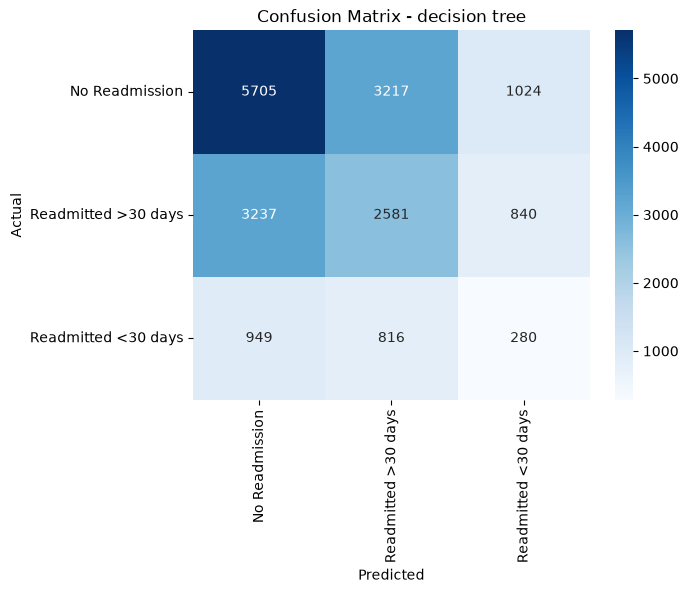

In [37]:
y_pred= decisiontree.predict(x_test)
print("FOR DECISION TREE")
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
accuracy=accuracy_score(y_test,y_pred)
print(f"Accuracy score: {accuracy}")
classification=classification_report(y_test,y_pred)
print("Classification report")
print(classification)
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Readmission', 'Readmitted >30 days', 'Readmitted <30 days'],
            yticklabels=['No Readmission', 'Readmitted >30 days', 'Readmitted <30 days'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - decision tree')
plt.show()

Random forest

In [38]:
from sklearn.ensemble import RandomForestClassifier
randomforest=RandomForestClassifier(n_estimators=200,random_state=42)
randomforest.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

FOR randomforest TREE
Accuracy score: 0.5734355729529733
Classification report
              precision    recall  f1-score   support

           0       0.60      0.85      0.70      9946
           1       0.50      0.33      0.40      6658
           2       0.37      0.00      0.01      2045

    accuracy                           0.57     18649
   macro avg       0.49      0.40      0.37     18649
weighted avg       0.54      0.57      0.52     18649

Confusion Matrix:
[[8458 1483    5]
 [4420 2226   12]
 [1315  720   10]]


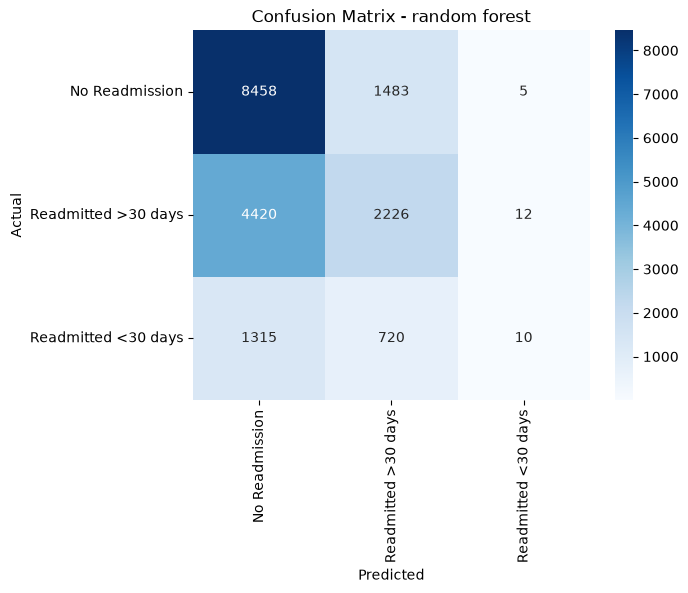

In [41]:
y_pred= randomforest.predict(x_test)
print("FOR randomforest TREE")
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
accuracy=accuracy_score(y_test,y_pred)
print(f"Accuracy score: {accuracy}")
classification=classification_report(y_test,y_pred)
print("Classification report")
print(classification)
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Readmission', 'Readmitted >30 days', 'Readmitted <30 days'],
            yticklabels=['No Readmission', 'Readmitted >30 days', 'Readmitted <30 days']
           )

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - random forest')
plt.show()